# 02 — DiD bulanan: kenapa desain ini ditinggalkan

**Status notebook ini: dokumentasi metodologi, bukan sumber estimasi kausal.**

Notebook ini mencatat percobaan mengukur efek frost Juli 2021 dengan
Difference-in-Differences pada data **bulanan**, dan kenapa percobaan itu tidak bisa
menjawab pertanyaan penelitian. Estimasi kausal proyek ini ada di notebook 04 (event study
harian). Notebook ini dipertahankan karena alasan penggantian desainnya adalah bagian dari
temuan.

Spesifikasi yang diuji, identik untuk ketiga tanggal event:

```
gap_t = log(arabica_t) − log(robusta_t)
gap ~ bin_0_5 + bin_6_11 + bin_12_18 + tren + log(brl_usd)
```

Jendela: 12 bulan pra-event, 18 bulan pasca-event, n = 31 observasi per event.

In [1]:
import sys
from pathlib import Path

sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

from src.ingestion.events import load_events
from src.processing.build_panel import load_panel
from src.processing.event_study import POST_MONTHS, PRE_MONTHS, _gap, compare_trend_specs, event_window

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 220)

panel = load_panel()
events = load_events("../data/events.csv")
used = events[events.use.isin(["treatment", "placebo"])].sort_values("event_date")

print(f"jendela: -{PRE_MONTHS} s/d +{POST_MONTHS} bulan, n = {PRE_MONTHS + POST_MONTHS + 1} per event")
used[["event_date", "event_type", "severity", "use"]]

jendela: -12 s/d +18 bulan, n = 31 per event


,event_date,event_type,severity,use
0,2016-07-01,frost_scare,none,placebo
1,2019-07-01,frost_scare,none,placebo
2,2021-07-20,frost,severe,treatment


## Kenapa dua versi kontrol tren dilaporkan, bukan satu

Selisih harga Arabika–Robusta sudah menanjak **sebelum** frost Juli 2021 — kekeringan
2020–21 dan tahun *off-year* siklus biennial, keduanya khusus Arabika. Tren waktu karena
itu wajib dikontrol; tanpa itu, kenaikan yang sudah berjalan akan terhitung sebagai efek
frost.

Masalahnya, **cara mengontrol tren menentukan hasilnya**, dan dua cara yang sama-sama
lazim memberi jawaban berbeda:

**(a) Tren full-window** — satu garis lurus dicocokkan ke seluruh 31 bulan (pra + pasca).
Efek yang diperkirakan **menanjak bertahap sampai puncak di bulan ~11** bentuknya nyaris
sama dengan garis lurus menanjak. Tren dan efek jadi hampir kolinear, sehingga tren bisa
**menyerap sebagian efek yang seharusnya ia ukur**.

**(b) Tren pre-only (praktik baku *interrupted time series*)** — garis tren diestimasi
**hanya dari 12 bulan pra-event**, lalu diproyeksikan ke depan sebagai *counterfactual*.
Efek diukur sebagai simpangan dari proyeksi itu, sehingga tren tidak bisa menyerap efek.

**Keduanya dilaporkan justru karena hasilnya berbeda.** Memilih salah satu setelah melihat
mana yang lebih mendukung hipotesis adalah seleksi berbasis hasil. Kalau sebuah temuan
hanya muncul di satu dari dua spesifikasi yang sama-sama masuk akal, temuan itu rapuh, dan
pembaca berhak tahu.

## Hipotesis yang diuji

Jika efek yang terukur di 2021 berasal dari kerusakan pasokan akibat frost:

1. Koefisien 2021 pada bin **6–11 bulan** positif dan **stabil** di kedua versi
   (mekanisme ICO: dampak produksi masuk di tahun panen 2022/23).
2. Placebo 2016 dan 2019 — frost yang **tidak** merusak — kecil atau nol.
3. Koreksi tren pre-only **memperbesar** estimasi 2021, karena versi full-window diduga
   menyerap sebagian efek.

In [2]:
comparison = pd.concat([compare_trend_specs(panel, r.event_date) for _, r in used.iterrows()])

# Hanya besaran yang dilaporkan. Standard error dan p-value sengaja tidak ditampilkan:
# lihat bagian "Kenapa tidak ada p-value" di bawah.
effect_pct = comparison["pct"].unstack("bin")[["post_0_5", "post_6_11", "post_12_18"]]
effect_pct.columns = ["0-5 bln (%)", "6-11 bln (%)", "12-18 bln (%)"]
print("Efek pada selisih harga Arabika-Robusta, dalam persen")
print()
print(effect_pct.round(1).to_string())

Efek pada selisih harga Arabika-Robusta, dalam persen

                              0-5 bln (%)  6-11 bln (%)  12-18 bln (%)
event   versi                                                         
2016-07 (a) tren full-window         -8.4         -23.5          -26.4
        (b) tren pre-only           -10.9         -27.3          -31.9
2019-07 (a) tren full-window          5.4           7.4           -1.2
        (b) tren pre-only             7.7          19.4           14.9
2021-07 (a) tren full-window         -0.4          11.4            1.1
        (b) tren pre-only            -2.1           7.2           -3.5


In [3]:
# Ketidakstabilan: seberapa jauh estimasi bergeser hanya karena cara mengontrol tren.
a = effect_pct.xs("(a) tren full-window", level="versi")
b = effect_pct.xs("(b) tren pre-only", level="versi")
shift = (b - a).round(1)
flip = (np.sign(a) != np.sign(b)) & (a.abs() > 0.5) & (b.abs() > 0.5)

print("Pergeseran estimasi dari versi (a) ke (b), poin persen")
print()
print(shift.to_string())
print()
print("Bin yang tandanya berbalik antar-versi:")
for event, row in flip.iterrows():
    for col, flipped in row.items():
        if flipped:
            print(f"  {event} {col}: {a.loc[event, col]:+.1f}% -> {b.loc[event, col]:+.1f}%")

Pergeseran estimasi dari versi (a) ke (b), poin persen

         0-5 bln (%)  6-11 bln (%)  12-18 bln (%)
event                                            
2016-07         -2.5          -3.7           -5.5
2019-07          2.3          12.0           16.1
2021-07         -1.8          -4.2           -4.6

Bin yang tandanya berbalik antar-versi:
  2019-07 12-18 bln (%): -1.2% -> +14.9%
  2021-07 12-18 bln (%): +1.1% -> -3.5%


## Interpretasi: yang relevan adalah ketidakstabilannya

**Pada n=31 dengan satu event, tidak ada estimator standard error yang dapat diandalkan;
p-value tidak dilaporkan. Yang relevan dari notebook ini adalah ketidakstabilan estimasi,
bukan signifikansinya.**

**Besaran dan ketidakstabilannya:**

| Event | Bin | (a) full-window | (b) pre-only | Pergeseran |
|---|---|---|---|---|
| 2021 (damage) | 6–11 bln | +11,4% | +7,2% | −4,2 poin, **sepertiga hilang** |
| 2021 (damage) | 12–18 bln | +1,1% | −3,5% | **tanda berbalik** |
| 2019 (scare) | 6–11 bln | +7,4% | +19,4% | +12,0 poin, **naik 2,6×** |
| 2019 (scare) | 12–18 bln | −1,2% | +14,9% | **tanda berbalik** |
| 2016 (scare) | 12–18 bln | −26,4% | −31,9% | −5,5 poin |

Satu perubahan spesifikasi yang sama-sama bisa dipertahankan secara metodologis sudah
cukup untuk menghapus sepertiga estimasi 2021, membalik tanda di dua bin, dan melipatgandakan
estimasi placebo. Estimasi yang bergerak sebesar itu karena pilihan teknis tidak bisa
menjadi dasar klaim kausal, berapa pun p-value-nya.

**Terhadap tiga hipotesis:**

1. **Hanya tanda yang bertahan.** Koefisien 2021 pada bin 6–11 bulan positif di kedua versi
   (+11,4% dan +7,2%), tepat di jendela yang diramalkan mekanisme ICO. Besarannya tidak stabil.
2. **Placebo tidak kecil.** Placebo 2019 lebih besar daripada treatment 2021 di versi (b),
   di bin 6–11 dan 12–18 bulan. Placebo 2016 bergerak kuat ke arah negatif, yang hampir
   pasti mengukur kemerosotan panjang harga Arabika 2017–18, bukan frost.
3. **Ditolak.** Koreksi pre-only justru **mengecilkan** estimasi 2021. Penyebabnya bisa
   dilacak: tren pra-event 2021 positif, sehingga counterfactual-nya ikut menanjak dan
   simpangan terhadapnya menyusut. Koreksi itu tetap benar dilakukan — ia benar terlepas
   dari arah hasilnya — tapi tidak menyelamatkan desain ini.

## Kenapa tidak ada p-value

Versi awal notebook ini melaporkan p-value dari standard error HAC dengan `maxlags=12`.
Angka-angka itu **ditarik** dan tidak boleh dikutip.

Aturan lag yang lazim untuk HAC adalah `4·(T/100)^(2/9)`, yang untuk T=31 menghasilkan
**3**, bukan 12. Dengan 12 lag pada sampel sekecil ini estimatornya rusak: standard error
yang dihasilkan justru lebih kecil daripada OLS biasa, padahal koreksi untuk residual yang
berautokorelasi positif semestinya **membesarkan** standard error. Itu kegagalan estimator,
bukan presisi.

Lag sudah diperbaiki ke 3, tapi p-value tetap tidak dilaporkan, karena masalahnya lebih
dalam dari pilihan lag. Dengan 31 observasi, satu event, dan residual yang berautokorelasi,
**tidak ada** estimator standard error yang bisa diandalkan — dan mencoba estimator satu per
satu sampai ada yang memberi p-value "bagus" adalah seleksi berbasis hasil. Jadi yang
dilaporkan hanya yang bisa dipertanggungjawabkan: besaran koefisien dan seberapa besar ia
bergeser.

## Visual: harga aktual vs counterfactual

**Hipotesis:** jika frost menyebabkan lonjakan, garis aktual akan memisahkan diri ke atas
dari garis proyeksi setelah k = 0 — dan hanya pada event yang benar-benar merusak.

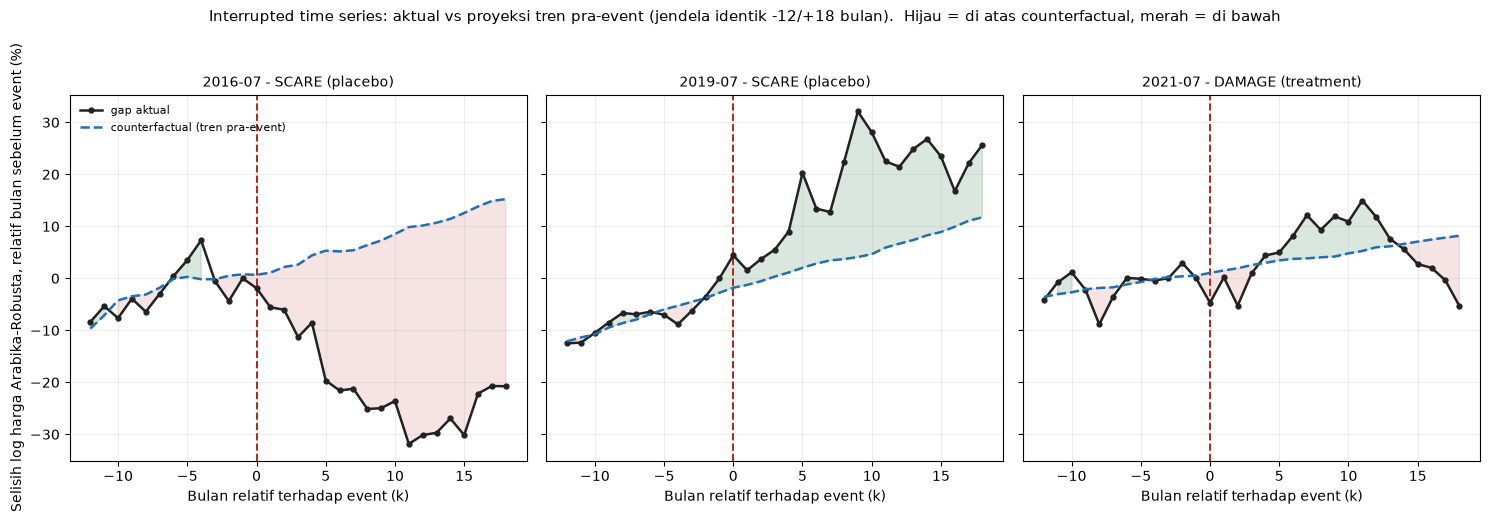

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2), sharey=True)
titles = {
    "2016-07": "2016-07 - SCARE (placebo)",
    "2019-07": "2019-07 - SCARE (placebo)",
    "2021-07": "2021-07 - DAMAGE (treatment)",
}

for ax, (_, r) in zip(axes, used.iterrows()):
    w = event_window(panel, r.event_date)
    g = _gap(w)
    Xw = sm.add_constant(pd.DataFrame(
        {"trend": w.k.values, "log_brl": np.log(w.brl_usd).values}, index=w.index
    ))
    pre_w = w[w.k < 0]
    fit_pre = sm.OLS(g.loc[pre_w.index], Xw.loc[pre_w.index]).fit()
    cf = fit_pre.predict(Xw)
    base = g.loc[w.index[w.k == -1]].iloc[0]

    ax.axvline(0, color="#B3241C", ls="--", lw=1.4)
    ax.plot(w.k, (g - base) * 100, color="#222", lw=1.8, marker="o", ms=3.5, label="gap aktual")
    ax.plot(w.k, (cf - base) * 100, color="#1F6FB2", lw=1.8, ls="--",
            label="counterfactual (tren pra-event)")
    ax.fill_between(w.k, (cf - base) * 100, (g - base) * 100,
                    where=(g >= cf), color="#1B6B3A", alpha=0.16)
    ax.fill_between(w.k, (cf - base) * 100, (g - base) * 100,
                    where=(g < cf), color="#B3241C", alpha=0.12)

    ax.set_title(titles[f"{r.event_date:%Y-%m}"], fontsize=10)
    ax.set_xlabel("Bulan relatif terhadap event (k)")
    ax.grid(alpha=0.22)

axes[0].set_ylabel("Selisih log harga Arabika-Robusta, relatif bulan sebelum event (%)")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.suptitle(
    "Interrupted time series: aktual vs proyeksi tren pra-event (jendela identik -12/+18 bulan)."
    "  Hijau = di atas counterfactual, merah = di bawah",
    fontsize=11,
)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(FIG_DIR / "06_its_counterfactual.png", dpi=150)
plt.show()

**Interpretasi:**

Panel 2021 memperlihatkan pola yang paling sesuai teori: aktual menempel pada
counterfactual selama ~5 bulan, naik di atasnya sekitar bulan 6–11, lalu jatuh ke bawahnya
setelah bulan 12 — cocok dengan mekanisme panen tertunda.

Tapi panel 2019 memperlihatkan **pemisahan ke atas yang lebih besar dan lebih lama**,
padahal ICO mencatat kekhawatiran frost saat itu mereda tanpa kerusakan. Selama dua panel
itu tidak bisa dibedakan, desain ini tidak bisa mengklaim efek kausal untuk 2021.

Panel 2016 menunjukkan hal ketiga: aktual jatuh jauh di bawah counterfactual, sejalan
dengan kemerosotan Arabika 2017–18 yang tidak ada hubungannya dengan frost.

## Kenapa desain bulanan ditinggalkan

1. **Tiga guncangan khusus Arabika berimpit.** Kekeringan 2020–21, tahun off-year biennial,
   dan frost Juli 2021 bergerak ke arah yang sama. Pada resolusi bulanan ketiganya menyatu
   menjadi satu garis menanjak.
2. **Placebo tidak bisa diinterpretasikan.** Jendela pasca-event 2019 (Jul 2019 – Jan 2021)
   tumpang tindih 7 bulan dengan jendela pra-event 2021 (Jul 2020 – Jun 2021). Placebo yang
   periode pasca-nya memuat penumpukan menjelang treatment tidak membawa informasi — ini
   bukan "placebo mengalahkan treatment", melainkan placebo yang tidak sah.
3. **Estimasi tidak stabil.** Satu perubahan spesifikasi yang bisa dipertahankan menggeser
   estimasi 2021 sepertiga dan membalik tanda di dua bin.

**Yang bertahan:** tanda positif 2021 pada bin 6–11 bulan, di jendela yang diramalkan
mekanisme ICO.

**Pengganti:** event study harian (notebook 04). Jendela dua minggu kebal terhadap
kekeringan dan siklus biennial yang bergerak dalam hitungan bulan, dan jendela harian 2016,
2019, serta 2021 tidak tumpang tindih — sehingga placebo menjadi sah.